In [2]:
from pathlib import Path
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

RANDOM_STATE = 42

print("Library load complete")

Library load complete


In [3]:
BASE_DIR = Path("..")
DATA_DIR = BASE_DIR / "data" / "raw"
RESULT_DIR = BASE_DIR / "results"

RESULT_DIR.mkdir(exist_ok=True)

X = pd.read_csv(
    DATA_DIR / "secom.data",
    sep=r"\s+",
    header=None
)

labels = pd.read_csv(
    DATA_DIR / "secom_labels.data",
    sep=r"\s+",
    header=None
)

y = labels.iloc[:, 0].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nLabel distribution")
print(y.value_counts())

X shape: (1567, 590)
y shape: (1567,)

Label distribution
0
-1    1463
 1     104
Name: count, dtype: int64


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Train shape:", X_train.shape)
print("Test shape :", X_test.shape)

print("\nTrain labels")
print(y_train.value_counts())

print("\nTest labels")
print(y_test.value_counts())

Train shape: (1253, 590)
Test shape : (314, 590)

Train labels
0
-1    1170
 1      83
Name: count, dtype: int64

Test labels
0
-1    293
 1     21
Name: count, dtype: int64


In [5]:
# Train 데이터 기준 결측률 계산
train_missing_ratio = X_train.isna().mean()

# 결측률 50% 이상 변수
high_missing_cols = train_missing_ratio[
    train_missing_ratio >= 0.5
].index.tolist()

# Train 기준으로 Train/Test 모두 동일한 변수 제거
X_train_hm = X_train.drop(columns=high_missing_cols)
X_test_hm = X_test.drop(columns=high_missing_cols)

print("High missing columns:", len(high_missing_cols))
print("Before:", X_train.shape[1])
print("After :", X_train_hm.shape[1])

High missing columns: 24
Before: 590
After : 566


In [6]:
train_unique_counts = X_train_hm.nunique(dropna=True)

constant_cols = train_unique_counts[
    train_unique_counts <= 1
].index.tolist()

X_train_clean = X_train_hm.drop(columns=constant_cols)
X_test_clean = X_test_hm.drop(columns=constant_cols)

print("Constant columns:", len(constant_cols))
print("Before:", X_train_hm.shape[1])
print("After :", X_train_clean.shape[1])

Constant columns: 116
Before: 566
After : 450


In [8]:
imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train_clean)
X_test_imputed = imputer.transform(X_test_clean)

print("Train shape:", X_train_imputed.shape)
print("Test shape :", X_test_imputed.shape)

print("Train missing:", np.isnan(X_train_imputed).sum())
print("Test missing :", np.isnan(X_test_imputed).sum())

Train shape: (1253, 450)
Test shape : (314, 450)
Train missing: 0
Test missing : 0


In [9]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("Train shape:", X_train_scaled.shape)
print("Test shape :", X_test_scaled.shape)

print("Train mean:", X_train_scaled.mean())
print("Train std :", X_train_scaled.std())

Train shape: (1253, 450)
Test shape : (314, 450)
Train mean: -6.971850111896345e-18
Train std : 1.0


In [10]:
# Linear SVM
linear_svm = SVC(
    kernel="linear",
    C=1.0,
    class_weight="balanced"
)

start = time.time()

linear_svm.fit(
    X_train_scaled,
    y_train
)

linear_time = time.time() - start

print("Linear SVM training complete")
print("Training time:", linear_time)
print("Support vectors:", linear_svm.n_support_)

Linear SVM training complete
Training time: 0.14121198654174805
Support vectors: [175  64]


In [11]:
# 예측
linear_pred = linear_svm.predict(X_test_scaled)

# ROC-AUC 계산용 decision score
linear_score = linear_svm.decision_function(X_test_scaled)

# 평가 지표
linear_accuracy = accuracy_score(y_test, linear_pred)

linear_bal_acc = balanced_accuracy_score(
    y_test,
    linear_pred
)

linear_recall = recall_score(
    y_test,
    linear_pred,
    pos_label=1
)

linear_f1 = f1_score(
    y_test,
    linear_pred,
    pos_label=1
)

linear_auc = roc_auc_score(
    (y_test == 1).astype(int),
    linear_score
)

linear_cm = confusion_matrix(
    y_test,
    linear_pred,
    labels=[-1, 1]
)

print("=== Linear SVM ===")
print(f"Accuracy          : {linear_accuracy:.4f}")
print(f"Balanced Accuracy : {linear_bal_acc:.4f}")
print(f"Fail Recall       : {linear_recall:.4f}")
print(f"Fail F1           : {linear_f1:.4f}")
print(f"ROC-AUC           : {linear_auc:.4f}")
print(f"Training Time     : {linear_time:.4f} sec")

print("\nConfusion Matrix")
print(linear_cm)

=== Linear SVM ===
Accuracy          : 0.8567
Balanced Accuracy : 0.5475
Fail Recall       : 0.1905
Fail F1           : 0.1509
ROC-AUC           : 0.6096
Training Time     : 0.1412 sec

Confusion Matrix
[[265  28]
 [ 17   4]]


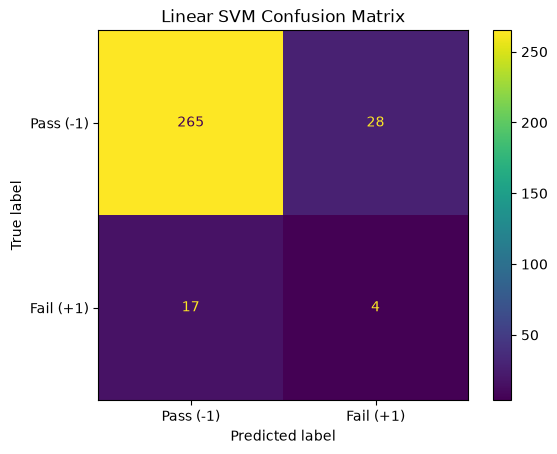

In [12]:
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(
    confusion_matrix=linear_cm,
    display_labels=["Pass (-1)", "Fail (+1)"]
)

disp.plot()
plt.title("Linear SVM Confusion Matrix")
plt.show()

In [13]:
# RBF SVM
rbf_svm = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    class_weight="balanced"
)

start = time.time()

rbf_svm.fit(
    X_train_scaled,
    y_train
)

rbf_time = time.time() - start

print("RBF SVM training complete")
print("Training time:", rbf_time)
print("Support vectors:", rbf_svm.n_support_)

RBF SVM training complete
Training time: 0.11046481132507324
Support vectors: [665  83]


In [16]:
# 예측
rbf_pred = rbf_svm.predict(X_test_scaled)

# ROC-AUC 계산용 decision score
rbf_score = rbf_svm.decision_function(X_test_scaled)

# 평가 지표
rbf_accuracy = accuracy_score(y_test, rbf_pred)

rbf_bal_acc = balanced_accuracy_score(
    y_test,
    rbf_pred
)

rbf_recall = recall_score(
    y_test,
    rbf_pred,
    pos_label=1
)

rbf_f1 = f1_score(
    y_test,
    rbf_pred,
    pos_label=1
)

rbf_auc = roc_auc_score(
    (y_test == 1).astype(int),
    rbf_score
)

rbf_cm = confusion_matrix(
    y_test,
    rbf_pred,
    labels=[-1, 1]
)

print("=== RBF SVM ===")
print(f"Accuracy          : {rbf_accuracy:.4f}")
print(f"Balanced Accuracy : {rbf_bal_acc:.4f}")
print(f"Fail Recall       : {rbf_recall:.4f}")
print(f"Fail F1           : {rbf_f1:.4f}")
print(f"ROC-AUC           : {rbf_auc:.4f}")
print(f"Training Time     : {rbf_time:.4f} sec")

print("\nConfusion Matrix")
print(rbf_cm)

=== RBF SVM ===
Accuracy          : 0.9268
Balanced Accuracy : 0.5187
Fail Recall       : 0.0476
Fail F1           : 0.0800
ROC-AUC           : 0.6329
Training Time     : 0.1105 sec

Confusion Matrix
[[290   3]
 [ 20   1]]


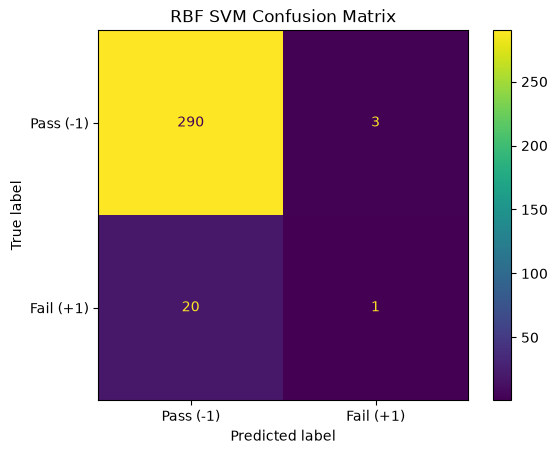

In [15]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=rbf_cm,
    display_labels=["Pass (-1)", "Fail (+1)"]
)

disp.plot()
plt.title("RBF SVM Confusion Matrix")
plt.show()

In [17]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

In [18]:
# RBF SVM hyperparameter tuning
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

param_grid = {
    "C": [0.1, 1, 10, 100],
    "gamma": [0.0005, 0.001, 0.002, 0.005, 0.01]
}

grid_rbf = GridSearchCV(
    estimator=SVC(
        kernel="rbf",
        class_weight="balanced"
    ),
    param_grid=param_grid,
    scoring="balanced_accuracy",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

start = time.time()

grid_rbf.fit(
    X_train_scaled,
    y_train
)

grid_time = time.time() - start

print("Grid Search complete")
print("Best parameters:", grid_rbf.best_params_)
print("Best CV Balanced Accuracy:", grid_rbf.best_score_)
print("Search time:", grid_time)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Grid Search complete
Best parameters: {'C': 0.1, 'gamma': 0.002}
Best CV Balanced Accuracy: 0.6060960281548518
Search time: 7.933945178985596


In [19]:
# Grid Search에서 찾은 최적 RBF 모델
best_rbf = grid_rbf.best_estimator_

# Test 예측
best_rbf_pred = best_rbf.predict(X_test_scaled)

# ROC-AUC 계산용 decision score
best_rbf_score = best_rbf.decision_function(X_test_scaled)

# 평가 지표
best_rbf_accuracy = accuracy_score(
    y_test,
    best_rbf_pred
)

best_rbf_bal_acc = balanced_accuracy_score(
    y_test,
    best_rbf_pred
)

best_rbf_recall = recall_score(
    y_test,
    best_rbf_pred,
    pos_label=1
)

best_rbf_f1 = f1_score(
    y_test,
    best_rbf_pred,
    pos_label=1
)

best_rbf_auc = roc_auc_score(
    (y_test == 1).astype(int),
    best_rbf_score
)

best_rbf_cm = confusion_matrix(
    y_test,
    best_rbf_pred,
    labels=[-1, 1]
)

print("=== Tuned RBF SVM ===")
print("Best C            :", grid_rbf.best_params_["C"])
print("Best gamma        :", grid_rbf.best_params_["gamma"])
print(f"Accuracy          : {best_rbf_accuracy:.4f}")
print(f"Balanced Accuracy : {best_rbf_bal_acc:.4f}")
print(f"Fail Recall       : {best_rbf_recall:.4f}")
print(f"Fail F1           : {best_rbf_f1:.4f}")
print(f"ROC-AUC           : {best_rbf_auc:.4f}")

print("\nConfusion Matrix")
print(best_rbf_cm)

=== Tuned RBF SVM ===
Best C            : 0.1
Best gamma        : 0.002
Accuracy          : 0.8089
Balanced Accuracy : 0.6324
Fail Recall       : 0.4286
Fail F1           : 0.2308
ROC-AUC           : 0.6930

Confusion Matrix
[[245  48]
 [ 12   9]]


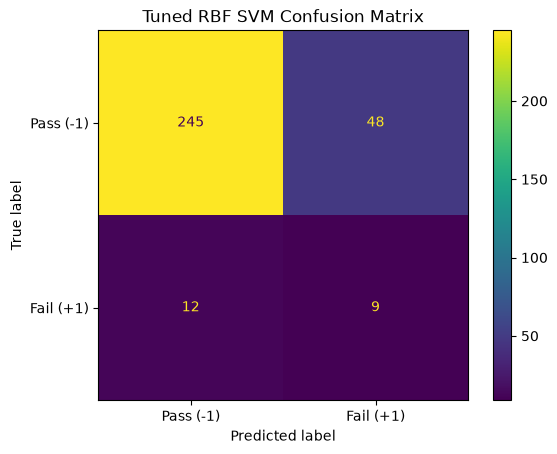

In [20]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=best_rbf_cm,
    display_labels=["Pass (-1)", "Fail (+1)"]
)

disp.plot()
plt.title("Tuned RBF SVM Confusion Matrix")
plt.show()

In [21]:
comparison = pd.DataFrame({
    "Model": [
        "Linear SVM",
        "RBF SVM",
        "Tuned RBF SVM"
    ],
    "Accuracy": [
        linear_accuracy,
        rbf_accuracy,
        best_rbf_accuracy
    ],
    "Balanced Accuracy": [
        linear_bal_acc,
        rbf_bal_acc,
        best_rbf_bal_acc
    ],
    "Fail Recall": [
        linear_recall,
        rbf_recall,
        best_rbf_recall
    ],
    "Fail F1": [
        linear_f1,
        rbf_f1,
        best_rbf_f1
    ],
    "ROC-AUC": [
        linear_auc,
        rbf_auc,
        best_rbf_auc
    ]
})

comparison.round(4)

,Model,Accuracy,Balanced Accuracy,Fail Recall,Fail F1,ROC-AUC
0,Linear SVM,0.8567,0.5475,0.1905,0.1509,0.6096
1,RBF SVM,0.9268,0.5187,0.0476,0.0800,0.6329
2,Tuned RBF SVM,0.8089,0.6324,0.4286,0.2308,0.6930


In [22]:
comparison.to_csv(
    RESULT_DIR / "svm_model_comparison.csv",
    index=False
)

print("Saved:", RESULT_DIR / "svm_model_comparison.csv")

Saved: ..\results\svm_model_comparison.csv


In [23]:
from sklearn.decomposition import PCA

In [24]:
pca90 = PCA(
    n_components=0.90,
    random_state=RANDOM_STATE
)

X_train_pca = pca90.fit_transform(X_train_scaled)
X_test_pca = pca90.transform(X_test_scaled)

print("Before PCA:", X_train_scaled.shape[1])
print("After PCA :", X_train_pca.shape[1])
print(
    "Explained variance:",
    pca90.explained_variance_ratio_.sum()
)

Before PCA: 450
After PCA : 127
Explained variance: 0.9012286920850962


In [25]:
from sklearn.pipeline import Pipeline

In [26]:
# PCA + RBF SVM Pipeline
pca_rbf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.90)),
    ("svc", SVC(
        kernel="rbf",
        class_weight="balanced"
    ))
])

param_grid_pca = {
    "svc__C": [0.1, 1, 10, 100],
    "svc__gamma": [0.0005, 0.001, 0.002, 0.005, 0.01]
}

grid_pca_rbf = GridSearchCV(
    estimator=pca_rbf_pipeline,
    param_grid=param_grid_pca,
    scoring="balanced_accuracy",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

start = time.time()

# PCA 이전의 450개 데이터 사용
grid_pca_rbf.fit(
    X_train_clean,
    y_train
)

pca_grid_time = time.time() - start

print("PCA + RBF Grid Search complete")
print("Best parameters:", grid_pca_rbf.best_params_)
print("Best CV Balanced Accuracy:", grid_pca_rbf.best_score_)
print("Search time:", pca_grid_time)

best_pca = grid_pca_rbf.best_estimator_.named_steps["pca"]

print(
    "PC count:",
    best_pca.n_components_
)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
PCA + RBF Grid Search complete
Best parameters: {'svc__C': 0.1, 'svc__gamma': 0.002}
Best CV Balanced Accuracy: 0.6094142785319256
Search time: 8.786243438720703
PC count: 127


In [27]:
# 최적 PCA + RBF 모델
best_pca_rbf = grid_pca_rbf.best_estimator_

# Test 예측
pca_rbf_pred = best_pca_rbf.predict(X_test_clean)

# Decision score
pca_rbf_score = best_pca_rbf.decision_function(X_test_clean)

# 평가
pca_rbf_accuracy = accuracy_score(
    y_test,
    pca_rbf_pred
)

pca_rbf_bal_acc = balanced_accuracy_score(
    y_test,
    pca_rbf_pred
)

pca_rbf_recall = recall_score(
    y_test,
    pca_rbf_pred,
    pos_label=1
)

pca_rbf_f1 = f1_score(
    y_test,
    pca_rbf_pred,
    pos_label=1
)

pca_rbf_auc = roc_auc_score(
    (y_test == 1).astype(int),
    pca_rbf_score
)

pca_rbf_cm = confusion_matrix(
    y_test,
    pca_rbf_pred,
    labels=[-1, 1]
)

print("=== PCA 90% + Tuned RBF SVM ===")
print("Best parameters    :", grid_pca_rbf.best_params_)
print(f"Accuracy           : {pca_rbf_accuracy:.4f}")
print(f"Balanced Accuracy  : {pca_rbf_bal_acc:.4f}")
print(f"Fail Recall        : {pca_rbf_recall:.4f}")
print(f"Fail F1            : {pca_rbf_f1:.4f}")
print(f"ROC-AUC            : {pca_rbf_auc:.4f}")

print("\nConfusion Matrix")
print(pca_rbf_cm)

=== PCA 90% + Tuned RBF SVM ===
Best parameters    : {'svc__C': 0.1, 'svc__gamma': 0.002}
Accuracy           : 0.7866
Balanced Accuracy  : 0.5983
Fail Recall        : 0.3810
Fail F1            : 0.1928
ROC-AUC            : 0.6771

Confusion Matrix
[[239  54]
 [ 13   8]]


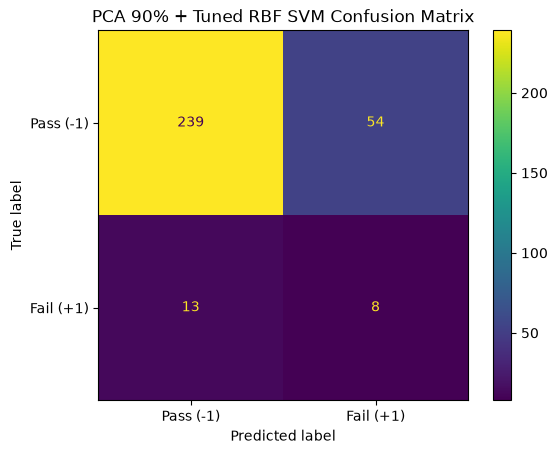

In [28]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=pca_rbf_cm,
    display_labels=["Pass (-1)", "Fail (+1)"]
)

disp.plot()
plt.title("PCA 90% + Tuned RBF SVM Confusion Matrix")
plt.show()

In [29]:
pca_row = pd.DataFrame({
    "Model": ["PCA90 + Tuned RBF SVM"],
    "Accuracy": [pca_rbf_accuracy],
    "Balanced Accuracy": [pca_rbf_bal_acc],
    "Fail Recall": [pca_rbf_recall],
    "Fail F1": [pca_rbf_f1],
    "ROC-AUC": [pca_rbf_auc]
})

comparison_final = pd.concat(
    [comparison, pca_row],
    ignore_index=True
)

comparison_final.round(4)

,Model,Accuracy,Balanced Accuracy,Fail Recall,Fail F1,ROC-AUC
0,Linear SVM,0.8567,0.5475,0.1905,0.1509,0.6096
1,RBF SVM,0.9268,0.5187,0.0476,0.0800,0.6329
2,Tuned RBF SVM,0.8089,0.6324,0.4286,0.2308,0.6930
3,PCA90 + Tuned RBF SVM,0.7866,0.5983,0.3810,0.1928,0.6771


In [30]:
comparison_final.to_csv(
    RESULT_DIR / "svm_model_comparison_final.csv",
    index=False
)

print(
    "Saved:",
    RESULT_DIR / "svm_model_comparison_final.csv"
)

Saved: ..\results\svm_model_comparison_final.csv


지금 부터는 기본 성능 뿐만 아니라 서포트 벡터 머신의 성능을 조금 더 끌어올릴 수 있는 방법에 대한 실험을 진행 해보겠다.

In [31]:
from sklearn.model_selection import cross_val_predict

In [32]:
threshold_svm = SVC(
    kernel="rbf",
    C=0.1,
    gamma=0.002,
    class_weight="balanced"
)

oof_scores = cross_val_predict(
    threshold_svm,
    X_train_scaled,
    y_train,
    cv=cv,
    method="decision_function",
    n_jobs=-1
)

print("OOF scores complete")
print("Min score:", oof_scores.min())
print("Max score:", oof_scores.max())

OOF scores complete
Min score: -1.3443285550944113
Max score: 0.9005764107910086


In [33]:
thresholds = np.linspace(
    oof_scores.min(),
    oof_scores.max(),
    300
)

threshold_results = []

for threshold in thresholds:

    pred = np.where(
        oof_scores >= threshold,
        1,
        -1
    )

    bal_acc = balanced_accuracy_score(
        y_train,
        pred
    )

    recall = recall_score(
        y_train,
        pred,
        pos_label=1
    )

    f1 = f1_score(
        y_train,
        pred,
        pos_label=1
    )

    threshold_results.append([
        threshold,
        bal_acc,
        recall,
        f1
    ])

threshold_df = pd.DataFrame(
    threshold_results,
    columns=[
        "Threshold",
        "Balanced Accuracy",
        "Fail Recall",
        "Fail F1"
    ]
)

best_idx = threshold_df[
    "Balanced Accuracy"
].idxmax()

best_threshold = threshold_df.loc[
    best_idx,
    "Threshold"
]

print(
    threshold_df.loc[best_idx]
)

Threshold           -0.435855
Balanced Accuracy    0.621357
Fail Recall          0.746988
Fail F1              0.168707
Name: 121, dtype: float64


In [34]:
# 기존 Tuned RBF의 Test decision score 사용
threshold_test_pred = np.where(
    best_rbf_score >= best_threshold,
    1,
    -1
)

th_accuracy = accuracy_score(
    y_test,
    threshold_test_pred
)

th_bal_acc = balanced_accuracy_score(
    y_test,
    threshold_test_pred
)

th_recall = recall_score(
    y_test,
    threshold_test_pred,
    pos_label=1
)

th_f1 = f1_score(
    y_test,
    threshold_test_pred,
    pos_label=1
)

th_cm = confusion_matrix(
    y_test,
    threshold_test_pred,
    labels=[-1, 1]
)

print("=== Threshold Tuned RBF SVM ===")
print("Threshold         :", best_threshold)
print(f"Accuracy          : {th_accuracy:.4f}")
print(f"Balanced Accuracy : {th_bal_acc:.4f}")
print(f"Fail Recall       : {th_recall:.4f}")
print(f"Fail F1           : {th_f1:.4f}")

print("\nConfusion Matrix")
print(th_cm)

=== Threshold Tuned RBF SVM ===
Threshold         : -0.43585530803041206
Accuracy          : 0.5318
Balanced Accuracy : 0.6386
Fail Recall       : 0.7619
Fail F1           : 0.1788

Confusion Matrix
[[151 142]
 [  5  16]]


In [35]:
# C, gamma, class_weight 동시 튜닝

param_grid_weight = {
    "C": [0.03, 0.05, 0.1, 0.2, 0.5, 1.0],
    "gamma": [0.0005, 0.001, 0.002, 0.003, 0.005],
    "class_weight": [
        {-1: 1, 1: 3},
        {-1: 1, 1: 5},
        {-1: 1, 1: 7},
        {-1: 1, 1: 10},
        {-1: 1, 1: 15},
        "balanced"
    ]
}

grid_weight = GridSearchCV(
    SVC(kernel="rbf"),
    param_grid=param_grid_weight,
    scoring="balanced_accuracy",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

start = time.time()

grid_weight.fit(
    X_train_scaled,
    y_train
)

weight_grid_time = time.time() - start

print("Weighted RBF Grid Search complete")
print("Best parameters:", grid_weight.best_params_)
print("Best CV Balanced Accuracy:", grid_weight.best_score_)
print("Search time:", weight_grid_time)

Fitting 5 folds for each of 180 candidates, totalling 900 fits
Weighted RBF Grid Search complete
Best parameters: {'C': 0.05, 'class_weight': {-1: 1, 1: 15}, 'gamma': 0.003}
Best CV Balanced Accuracy: 0.6086695575666164
Search time: 21.650304794311523


In [36]:
from sklearn.feature_selection import SelectKBest, f_classif

In [37]:
feature_svm_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("select", SelectKBest(score_func=f_classif)),
    ("svc", SVC(
        kernel="rbf",
        class_weight="balanced"
    ))
])

param_grid_feature = {
    "select__k": [30, 50, 80, 120, 180, 250, 350, 450],
    "svc__C": [0.05, 0.1, 0.2, 0.5],
    "svc__gamma": [0.001, 0.002, 0.003, 0.005]
}

grid_feature = GridSearchCV(
    estimator=feature_svm_pipeline,
    param_grid=param_grid_feature,
    scoring="balanced_accuracy",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

start = time.time()

grid_feature.fit(
    X_train_clean,
    y_train
)

feature_grid_time = time.time() - start

print("Feature Selection + RBF complete")
print("Best parameters:", grid_feature.best_params_)
print(
    "Best CV Balanced Accuracy:",
    grid_feature.best_score_
)
print("Search time:", feature_grid_time)

Fitting 5 folds for each of 128 candidates, totalling 640 fits
Feature Selection + RBF complete
Best parameters: {'select__k': 30, 'svc__C': 0.5, 'svc__gamma': 0.003}
Best CV Balanced Accuracy: 0.656652212166918
Search time: 19.647606134414673


In [38]:
param_grid_feature_fine = {
    "select__k": [
        10, 15, 20, 25, 30, 35, 40, 50
    ],

    "svc__C": [
        0.3, 0.5, 0.8, 1.0, 2.0, 5.0
    ],

    "svc__gamma": [
        0.0015, 0.002, 0.0025,
        0.003, 0.004, 0.005
    ]
}

grid_feature_fine = GridSearchCV(
    estimator=feature_svm_pipeline,
    param_grid=param_grid_feature_fine,
    scoring="balanced_accuracy",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

start = time.time()

grid_feature_fine.fit(
    X_train_clean,
    y_train
)

fine_time = time.time() - start

print("Fine Feature Selection Search complete")
print(
    "Best parameters:",
    grid_feature_fine.best_params_
)
print(
    "Best CV Balanced Accuracy:",
    grid_feature_fine.best_score_
)
print(
    "Search time:",
    fine_time
)

Fitting 5 folds for each of 288 candidates, totalling 1440 fits
Fine Feature Selection Search complete
Best parameters: {'select__k': 35, 'svc__C': 2.0, 'svc__gamma': 0.004}
Best CV Balanced Accuracy: 0.66037267471091
Search time: 42.10092258453369


In [39]:
from sklearn.model_selection import (
    RepeatedStratifiedKFold,
    cross_validate
)
from sklearn.metrics import make_scorer

In [40]:
# 현재 최적 모델 고정
final_feature_svm = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("select", SelectKBest(
        score_func=f_classif,
        k=35
    )),
    ("svc", SVC(
        kernel="rbf",
        C=2.0,
        gamma=0.004,
        class_weight="balanced"
    ))
])

# 기존 Grid Search와 다른 CV 분할로 안정성 확인
repeat_cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=123
)

scoring = {
    "balanced_accuracy": "balanced_accuracy",

    "fail_recall": make_scorer(
        recall_score,
        pos_label=1
    ),

    "fail_f1": make_scorer(
        f1_score,
        pos_label=1
    ),

    "roc_auc": "roc_auc"
}

cv_result = cross_validate(
    final_feature_svm,
    X_train_clean,
    y_train,
    cv=repeat_cv,
    scoring=scoring,
    n_jobs=-1
)

print("=== Repeated CV Stability Check ===")

for metric in scoring.keys():

    values = cv_result[f"test_{metric}"]

    print(
        f"{metric:20s}: "
        f"{values.mean():.4f} ± {values.std():.4f}"
    )

=== Repeated CV Stability Check ===
balanced_accuracy   : 0.6099 ± 0.0530
fail_recall         : 0.4457 ± 0.1091
fail_f1             : 0.1930 ± 0.0431
roc_auc             : 0.6679 ± 0.0501


In [41]:
# 최종 Feature Selection + RBF 모델 학습
final_feature_svm.fit(
    X_train_clean,
    y_train
)

# Test 예측
feature_pred = final_feature_svm.predict(
    X_test_clean
)

feature_score = final_feature_svm.decision_function(
    X_test_clean
)

# 평가
feature_accuracy = accuracy_score(
    y_test,
    feature_pred
)

feature_bal_acc = balanced_accuracy_score(
    y_test,
    feature_pred
)

feature_recall = recall_score(
    y_test,
    feature_pred,
    pos_label=1
)

feature_f1 = f1_score(
    y_test,
    feature_pred,
    pos_label=1
)

feature_auc = roc_auc_score(
    (y_test == 1).astype(int),
    feature_score
)

feature_cm = confusion_matrix(
    y_test,
    feature_pred,
    labels=[-1, 1]
)

print("=== SelectKBest(35) + Tuned RBF SVM ===")
print(f"Accuracy          : {feature_accuracy:.4f}")
print(f"Balanced Accuracy : {feature_bal_acc:.4f}")
print(f"Fail Recall       : {feature_recall:.4f}")
print(f"Fail F1           : {feature_f1:.4f}")
print(f"ROC-AUC           : {feature_auc:.4f}")

print("\nConfusion Matrix")
print(feature_cm)

=== SelectKBest(35) + Tuned RBF SVM ===
Accuracy          : 0.7834
Balanced Accuracy : 0.6408
Fail Recall       : 0.4762
Fail F1           : 0.2273
ROC-AUC           : 0.7754

Confusion Matrix
[[236  57]
 [ 11  10]]


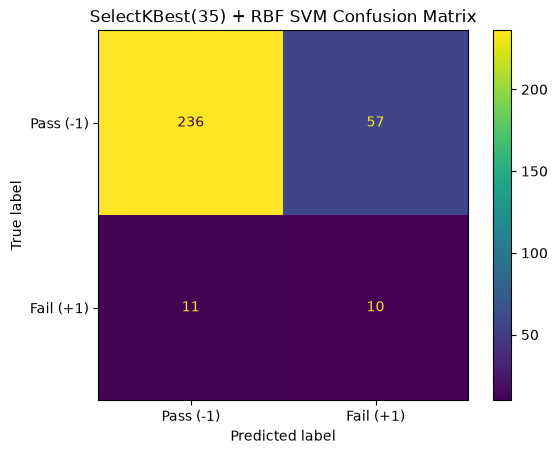

In [42]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=feature_cm,
    display_labels=["Pass (-1)", "Fail (+1)"]
)

disp.plot()
plt.title("SelectKBest(35) + RBF SVM Confusion Matrix")
plt.show()